<a href="https://colab.research.google.com/github/Airraad/Outage-Analysis/blob/main/Outage_Events.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Outage Dataset Analysis
- Ahmed, Peter, Jacob, Mark

Dataset can be accessed through: https://catalog.data.gov/dataset/event-correlated-outage-dataset-in-america?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSIsInEiOiJibGFjayAifQ%3D%3D
- **specifically using the eaglei_outages_with_events_2023_24_hour_lag**

First questions to come to mind are:
- Which events have the most outages
- Which locations on a map have the most outages.
- can we track severity?
- which time of year has the most outages?

Maybe focusing our big questions to **Where can we allocate resources to have less outages?**

#### Input data:
- Event
	- State of
	- date/time begin of
	- date/time restoration
	- event type
- Outage
	 - fips: county ID
	- state
	- county
	- start time
	- duration
	- min customers
	- max customer
	- mean customers
#### Outputs data:
- most state occurances
- most county occurances
- most event occurances
- most occurred month
- most event occurances
- severity: (Duration * weight) + (Mean customers * weight)
- (bonus if we have time) what's the growth rate of the mean customers relative to duration, is there a connection?
#### Duties:
- Clean events type column
- (test for accuracy?)
- sort by things we need to track and save them
- make a severity measure
- ...

In [ ]:
#Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re #for regex to use files wanted for specific checks
import plotly.express as px #for Heatmap



In [ ]:
#Data Importing
#Peter: importing data only using with_events files not including specified lag files
#       added support for the events with lag files
#       year and month cols added to df, df sorted by start_time
def import_data(lag=""):
  dfs = []
  for i in range(2014,2024):
    if lag == "":
      df = pd.read_csv(f"./Outage_Dataset/eaglei_outages_with_events_{i}.csv")
    elif lag == "8" or lag == "24" or lag == 8 or lag == 24:
      df = pd.read_csv(f"./Outage_Dataset/eaglei_outages_with_events_{i}_{lag}_hours_lag.csv")
    else:
      print("ERROR: Invalid input for lag. Valid input is 8 or 24.")
    df["year"] = int(i)
    df["month"] = pd.to_datetime(df["Datetime Event Began"]).dt.month
    df['start_time'] = pd.to_datetime(df['start_time'])
    df = df.sort_values(by='start_time', ascending=True).reset_index(drop=True)
    dfs.append(df)
  eagle_df = pd.concat(dfs, ignore_index=True)
  eagle_df

  return eagle_df


In [ ]:
#Cleaning
#Peter: Event Type needs to be cleaned and some types merged, doesn't seem to be any other issues
#       Merging what with what into what can be changed
def clean_events(eagle_df):
  unify = {
      # Weather
      "sever weather": "severe weather",
      "weather": "severe weather",
      "natural disaster": "weather or natural disaster",

      # Transmission
      "transmission disruption": "transmission interruption",
      "severe weather/transmisison interruption":
          "severe weather/transmission interruption",

      # Islanding
      "electrical system islanding": "islanding",

      # Physical attacks
      "actual physical attack": "physical attack",
      "potential physical attack": "physical attack",
      "suspected physical attack": "physical attack",
      "physical attack - other": "physical attack",
      "physical attack - generator loss or failure": "physical attack",

      # Vandalism
      "actual physical attack/vandalism": "physical attack/vandalism",
      "physical attack - vandalism": "physical attack/vandalism",
      "physical attack - vandalism - other": "physical attack/vandalism",
      "physical attack - vandalism - suspicious activity":
          "physical attack/vandalism",
      "physical attack - vandalism - theft - suspicious activity":
          "theft/vandalism",

      # Theft and vandalism
      "vandalism - suspicious activity": "vandalism",
      "vandalism - theft": "theft/vandalism",
      "vandalism - theft - suspicious activity": "theft/vandalism",
      "theft - other": "theft",
      "theft - suspicious activity": "theft",

      # Cyber
      "suspected cyber attack": "cyber attack",

      # Fuel
      "fuel supply deficiency": "fuel supply emergency",
  }
  clean_eagle = eagle_df.copy()
  clean_eagle["Event Type"] = (
      eagle_df["Event Type"]
      .str.replace("\xa0", " ", regex=False)
      .str.strip()
      .str.replace(r"^-\s*", "", regex=True)
      .str.replace(r"\s*-\s*", " - ", regex=True)
      .str.lower()
      .replace(unify)
      .str.title()
  )
  return clean_eagle





In [ ]:
#Meaure frequency, save as a df.
#Peter: frequency default state and Event Type but options allowed
  #Ahmed: Frequency of events per state, I'm pretty confused on how state ID is chosen but I think it seperatees counties.
def frequency(df, rows = "state", cols = "Event Type"):
  frequency_df = pd.crosstab(df[rows], df[cols], margins=True)
  return frequency_df

In [ ]:
#Severity
def severity(eagle, time =""):
  #Ahmed: I origionally wanted to use weights so we can sort of make a scale from 0->1 to measure how impactful something is, but I think the best bet (and because its easier) is to just calculate how many customer-hours per event there are

  eagle["severity"] = eagle["duration"] * eagle["mean_customers"]
  #Severity calc


  # Either 1) group by year and show severity per year
  if time == "":
    plot_severity = eagle.groupby('year')['severity'].sum()
    year_text = "year"
  # or 2) group by month (Given the year in the second function variable) and show severity per month.
  else:
    plot_severity = eagle[eagle['year']==int(time)].groupby('month')['severity'].sum()
    year_text = "month"


  # Generate the bar chart with range on the x-axis
  plt.figure(figsize=(10, 6))
  plot_severity.plot.bar(color='steelblue', edgecolor='black')

  plt.title(f'Total Outage Severity by {year_text}')
  plt.xlabel(year_text)
  plt.ylabel('Total Severity Score (Customer-Hours)')
  plt.xticks(rotation=45)
  plt.tight_layout()

  plt.show()

  return eagle

In [ ]:
#Ahmed: Going to make heatmap
def heatmap(severity_df, time = ''):
  #list all of states as initials
  us_states = {
    'Alabama': 'AL',
    'Alaska': 'AK',
    'Arizona': 'AZ',
    'Arkansas': 'AR',
    'California': 'CA',
    'Colorado': 'CO',
    'Connecticut': 'CT',
    'Delaware': 'DE',
    'Florida': 'FL',
    'Georgia': 'GA',
    'Hawaii': 'HI',
    'Idaho': 'ID',
    'Illinois': 'IL',
    'Indiana': 'IN',
    'Iowa': 'IA',
    'Kansas': 'KS',
    'Kentucky': 'KY',
    'Louisiana': 'LA',
    'Maine': 'ME',
    'Maryland': 'MD',
    'Massachusetts': 'MA',
    'Michigan': 'MI',
    'Minnesota': 'MN',
    'Mississippi': 'MS',
    'Missouri': 'MO',
    'Montana': 'MT',
    'Nebraska': 'NE',
    'Nevada': 'NV',
    'New Hampshire': 'NH',
    'New Jersey': 'NJ',
    'New Mexico': 'NM',
    'New York': 'NY',
    'North Carolina': 'NC',
    'North Dakota': 'ND',
    'Ohio': 'OH',
    'Oklahoma': 'OK',
    'Oregon': 'OR',
    'Pennsylvania': 'PA',
    'Rhode Island': 'RI',
    'South Carolina': 'SC',
    'South Dakota': 'SD',
    'Tennessee': 'TN',
    'Texas': 'TX',
    'Utah': 'UT',
    'Vermont': 'VT',
    'Virginia': 'VA',
    'Washington': 'WA',
    'West Virginia': 'WV',
    'Wisconsin': 'WI',
    'Wyoming': 'WY'}



  # 1. Map state names to initials vectorially (Fast and instant)
  if time == '':
    severity_df['init'] = severity_df['state'].map(us_states)
  else:
    severity_df = severity_df[severity_df['year'] == int(time)]

    severity_df['init'] = severity_df['state'].map(us_states)
  # 2. Aggregate severity by state for the map visualization
  aggregated_df = severity_df.groupby(['init', 'state'])['severity'].sum().reset_index()

  # 3. Create the USA choropleth map
  fig = px.choropleth(
    aggregated_df,
    locations='init',
    locationmode='USA-states',
    color='severity',
    scope='usa',
    color_continuous_scale='Reds',
    title='Total Power Outage Severity by State (Customer-Hours)'
  )

  return fig

In [ ]:
#Bonus if we have time, save for last
def growth_rate():
  #Jacob
    # Run functions to import and clean data
    eagle_df = import_data()
    eagle_df = clean_events(eagle_df)

    # Remove major outliers (remove bottom 5% and top 5% to get a better representation of data)
    cust_low = eagle_df['mean_customers'].quantile(0.05)
    cust_high = eagle_df['mean_customers'].quantile(0.95)
    dur_low = eagle_df['duration'].quantile(0.05)
    dur_high = eagle_df['duration'].quantile(0.95)

    #Create new data frame where outlier data removed
    growth_df = eagle_df[
        (eagle_df['mean_customers'] >= cust_low)
        & (eagle_df['mean_customers'] <= cust_high)
        & (eagle_df['duration'] >= dur_low)
        & (eagle_df['duration'] <= dur_high)
    ].copy() # .copy() - make this a new data frame, not a reference to first one

    # Generate a scatterplot to visualize length vs num. of customer relationship
    plt.figure(figsize=(10, 6))
    # x-axis. y-axis, color, opacity, color on perimeter of dots
    plt.scatter(growth_df['duration'],growth_df['mean_customers'],color='steelblue',alpha=0.5,edgecolor='black')
    # (x,y,deg) to calculate m and b using np.polyfit()
    m, b = np.polyfit(growth_df['duration'], growth_df['mean_customers'], 1)
    # .plot(data_col_used, m*x-var, b and y given from polyfit line above)
    plt.plot(growth_df['duration'], m * growth_df['duration'] + b, color='blue', linewidth=2)
    plt.xlabel('Duration (Hours)')
    plt.ylabel('Mean Customers Affected')
    plt.title('Outage Length vs Customers Affected (5th-95th Percentile)')
    plt.tight_layout()
    plt.savefig('Filtered_Outage_Duration_vs_Customers.png')
    plt.show()
    return growth_df


In [ ]:
#Ahmed: copied jacob's code and trying to do it for customer hours over time.
def severity_growth(eagle_df):

    # Remove major outliers (remove bottom 5% and top 5% to get a better representation of data)
    cust_low = eagle_df['severity'].quantile(0.05)
    cust_high = eagle_df['severity'].quantile(0.95)


    #Create new data frame where outlier data removed
    filtered_df = eagle_df[
        (eagle_df['severity'] >= cust_low)
        & (eagle_df['severity'] <= cust_high)
        & (eagle_df['year'])
    ].copy() # .copy() - make this a new data frame, not a reference to first one

    yearly_mean_df = filtered_df.groupby('year', as_index=False)['severity'].mean()

    # Generate a scatterplot to visualize length vs num. of customer relationship
    plt.figure(figsize=(10, 6))
    plt.scatter(
        yearly_mean_df['year'],
        yearly_mean_df['severity'],
        color='steelblue',
        alpha=0.8,
        edgecolor='black'
    )

    # Fit trendline to the yearly averages
    m, b = np.polyfit(yearly_mean_df['year'], yearly_mean_df['severity'], 1)
    plt.plot(yearly_mean_df['year'], m * yearly_mean_df['year'] + b, color='blue', linewidth=2)

    plt.xlabel('Years')
    plt.ylabel('Mean Severity')
    plt.title('Mean Severity by Year (5th-95th Percentile)')
    plt.tight_layout()
    plt.savefig('Filtered_Severity_Growth.png')
    plt.show()

    return yearly_mean_df


In [ ]:
#Execution of code
#Peter: testing if import data work and clean and printing df
df = import_data()
df = clean_events(df)
set(df["Event Type"])

{'Actual Physical Event',
 'Cyber Attack',
 'Cyber Event',
 'Distribution Interruption',
 'Distribution Interruption - Unknown Cause',
 'Failure At High Voltage Substation Or Switchyard',
 'Failure At High Voltage Substation Or Switchyard - Other',
 'Failure At High Voltage Substation Or Switchyard - Weather Or Natural Disaster',
 'Fuel Supply Emergency',
 'Fuel Supply Emergency - Coal',
 'Generation Inadequacy',
 'Islanding',
 'Natural Disaster/Transmission Interruption',
 'Other',
 'Physical Attack',
 'Physical Attack/Vandalism',
 'Public Appeal',
 'Sabotage',
 'Sabotage - Operator Action(S)',
 'Severe Weather',
 'Severe Weather - High Winds',
 'Severe Weather - Wind',
 'Severe Weather - Winter',
 'Severe Weather - Winter Storm',
 'Severe Weather/Distribution Interruption',
 'Severe Weather/Transmission Interruption',
 'Suspected Physical Attack - Vandalism',
 'Suspicious Activity',
 'System Operations',
 'Theft',
 'Theft/Vandalism',
 'Threat Of Physical Attack',
 'Transmission Equip

In [ ]:
#Peter: testing lag options for import data
dflag8 = import_data("8")
dflag8 = clean_events(dflag8)
set(dflag8["Event Type"])

{'Actual Physical Event',
 'Cyber Attack',
 'Cyber Event',
 'Distribution Interruption',
 'Distribution Interruption - Unknown Cause',
 'Failure At High Voltage Substation Or Switchyard',
 'Failure At High Voltage Substation Or Switchyard - Other',
 'Failure At High Voltage Substation Or Switchyard - Weather Or Natural Disaster',
 'Fuel Supply Emergency',
 'Fuel Supply Emergency - Coal',
 'Generation Inadequacy',
 'Islanding',
 'Natural Disaster/Transmission Interruption',
 'Other',
 'Physical Attack',
 'Physical Attack/Vandalism',
 'Public Appeal',
 'Sabotage',
 'Sabotage - Operator Action(S)',
 'Severe Weather',
 'Severe Weather - High Winds',
 'Severe Weather - Wind',
 'Severe Weather - Winter',
 'Severe Weather - Winter Storm',
 'Severe Weather/Distribution Interruption',
 'Severe Weather/Transmission Interruption',
 'Suspected Physical Attack - Vandalism',
 'Suspicious Activity',
 'System Operations',
 'Theft',
 'Theft/Vandalism',
 'Transmission Equipment Failure',
 'Transmission 

In [ ]:
#Peter: testing lag options for import data
dflag24 = import_data("24")
dflag24 = clean_events(dflag24)
set(dflag24["Event Type"])

{'Actual Physical Event',
 'Cyber Attack',
 'Cyber Event',
 'Distribution Interruption',
 'Distribution Interruption - Unknown Cause',
 'Failure At High Voltage Substation Or Switchyard',
 'Failure At High Voltage Substation Or Switchyard - Other',
 'Failure At High Voltage Substation Or Switchyard - Weather Or Natural Disaster',
 'Fuel Supply Emergency',
 'Fuel Supply Emergency - Coal',
 'Generation Inadequacy',
 'Islanding',
 'Natural Disaster/Transmission Interruption',
 'Other',
 'Physical Attack',
 'Physical Attack/Vandalism',
 'Public Appeal',
 'Sabotage',
 'Sabotage - Operator Action(S)',
 'Severe Weather',
 'Severe Weather - High Winds',
 'Severe Weather - Wind',
 'Severe Weather - Winter',
 'Severe Weather - Winter Storm',
 'Severe Weather/Distribution Interruption',
 'Severe Weather/Transmission Interruption',
 'Suspected Physical Attack - Vandalism',
 'Suspicious Activity',
 'System Operations',
 'Theft',
 'Theft/Vandalism',
 'Threat Of Physical Attack',
 'Transmission Equip

In [ ]:
#Peter: testing frequency
frequency(df)

Event Type,Actual Physical Event,Cyber Attack,Cyber Event,Distribution Interruption,Distribution Interruption - Unknown Cause,Failure At High Voltage Substation Or Switchyard,Failure At High Voltage Substation Or Switchyard - Other,Failure At High Voltage Substation Or Switchyard - Weather Or Natural Disaster,Fuel Supply Emergency,Fuel Supply Emergency - Coal,...,Transmission Equipment Failure,Transmission Interruption,Transmission Interruption/Distribution Interruption,Unknown,Unknown - Failure At High Voltage Substation Or Switchyard,Unknown - Vandalism,Vandalism,Weather Or Natural Disaster,Weather Or Natural Disaster - Other,All
state,,,,,,,,,,,,,,,,,,,,,
Alabama,0,0,0,0,0,0,0,0,0,0,...,0,144,0,0,0,0,239,76,0,6822
Arizona,0,0,0,0,0,0,0,0,5,0,...,0,22,0,0,0,0,16,0,0,274
Arkansas,0,0,0,0,0,0,0,0,0,9,...,0,236,0,0,0,0,105,106,0,3304
California,50,176,427,236,63,0,0,0,2727,0,...,0,911,0,58,0,74,10287,1007,0,61499
Colorado,0,0,10,0,0,0,0,0,0,0,...,0,298,0,0,0,0,112,0,0,771
Connecticut,0,1,0,0,0,0,0,0,0,0,...,0,0,0,24,0,0,0,73,0,1120
Delaware,0,0,3,0,0,0,0,0,0,0,...,0,0,0,0,0,0,25,0,0,74
Florida,0,0,416,0,0,0,0,0,0,0,...,0,968,0,78,0,0,1287,214,0,39338
Georgia,0,0,96,0,0,0,0,0,0,0,...,0,0,0,0,0,0,708,409,0,7374


#Ahmed: Enter the year you want to look through (severity), leave blank if you want to look at all:2021
#AhmedEnter lag demanded, either 8 or 24, leave blank if you want to show all:24


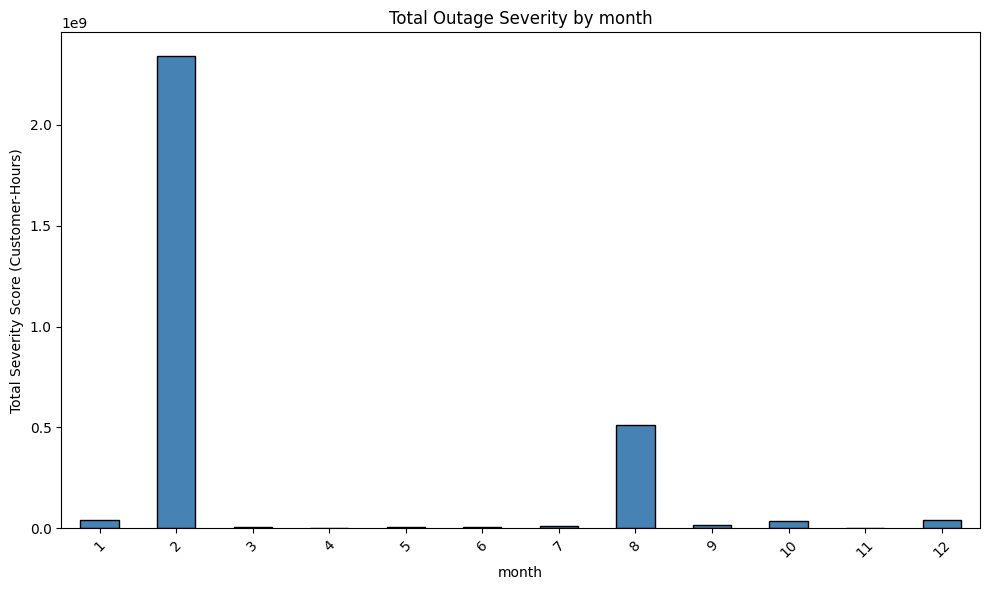

/tmp/ipykernel_524/1576206559.py:64: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



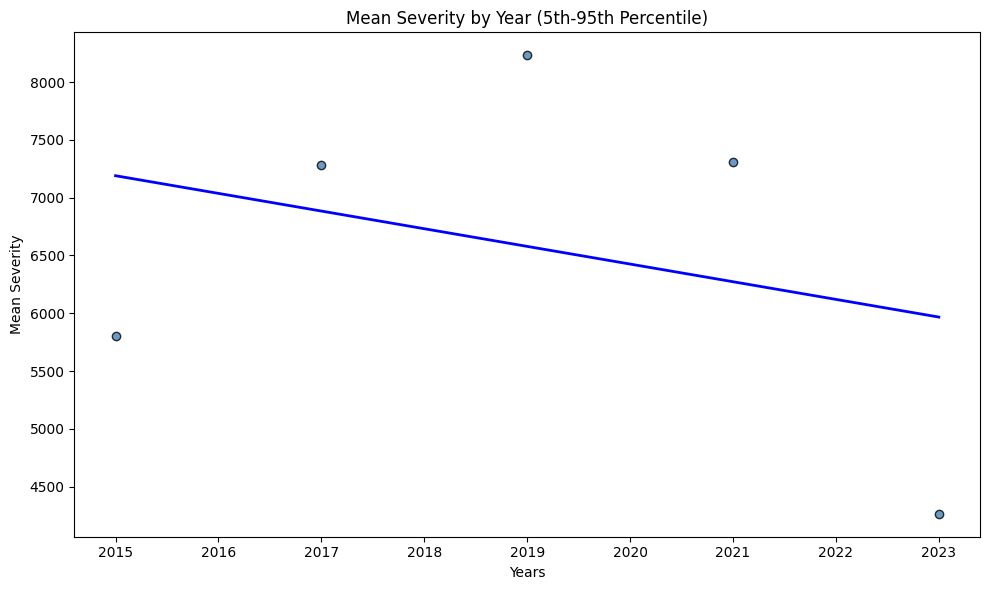

In [ ]:
#Ahmed: Testing Severity graph and State Heatmap

yea =(input("#Ahmed: Enter the year you want to look through (severity), leave blank if you want to look at all:"))
la = str(input("#AhmedEnter lag demanded, either 8 or 24, leave blank if you want to show all:"))
dflag = import_data(la)
dflag = clean_events(dflag)

# Calculate severity and show bar chart
dflag = severity(dflag, yea)

# Generate and display state heatmap
fig = heatmap(dflag, yea)
fig.show()

#Check for severity growth
dflag = severity_growth(dflag)

In [ ]:
#Curious as to why 2021 is so high so im going to paste frequency of each event

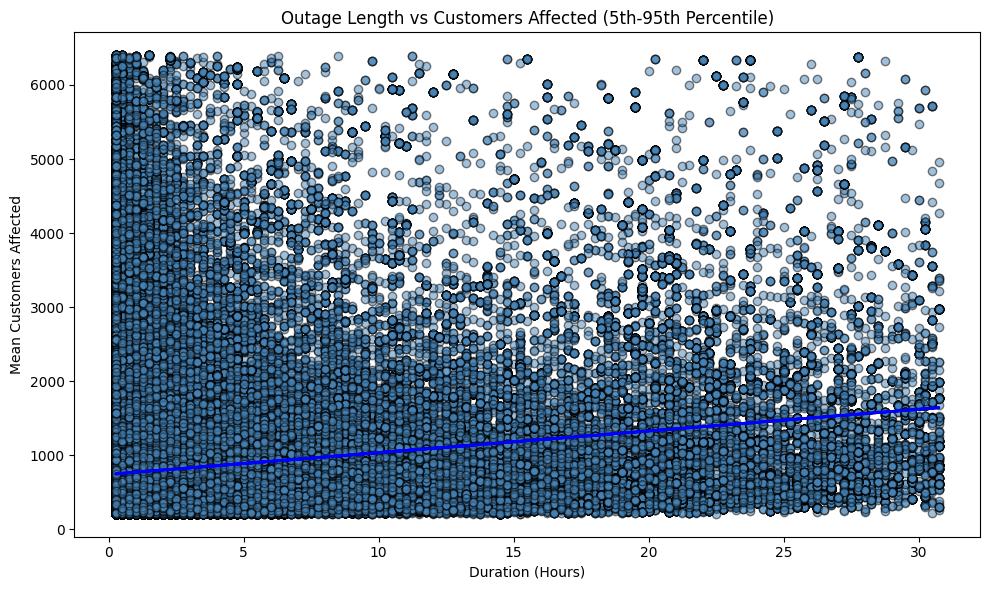

In [ ]:
growth_df = growth_rate() # test

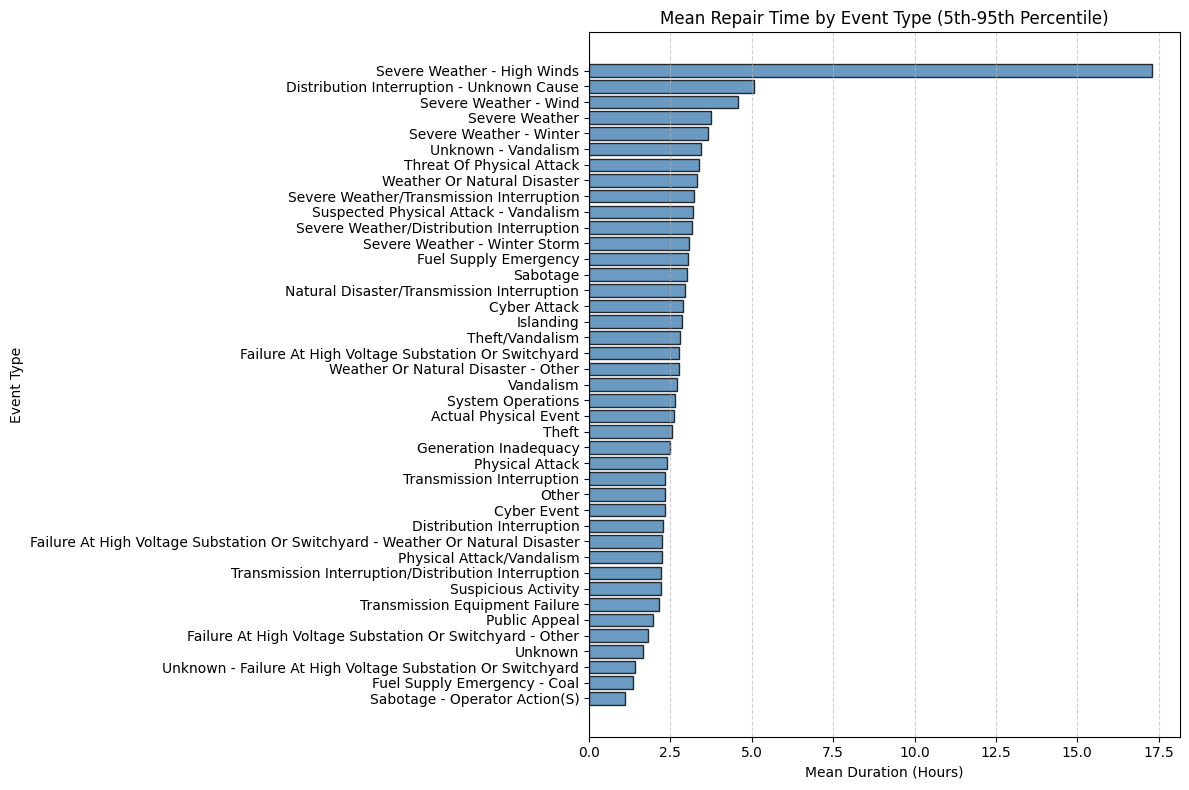

In [ ]:
#testing mean recovery time for each category of event type
#Jacob
def repair_time_by_type():
    eagle_df = import_data()
    eagle_df = clean_events(eagle_df)

    dur_low = eagle_df['duration'].quantile(0.05) #bottom 5%
    dur_high = eagle_df['duration'].quantile(0.95) #top 5%

    filtered_df = eagle_df[ # remove top and bottom 5% to get a more accurate spread
        (eagle_df['duration'] >= dur_low) &
        (eagle_df['duration'] <= dur_high)
    ].copy() #new, not reference

    mttr_df = filtered_df.groupby('Event Type')['duration'].mean().reset_index() # group into event types and use duration column
    mttr_df = mttr_df.sort_values(by='duration', ascending=True)  # ascending so longest duration is at the top

    plt.figure(figsize=(12, 8)) #create plot figure
    plt.barh(mttr_df['Event Type'], mttr_df['duration'], color='steelblue', edgecolor='black', alpha=0.8)

    plt.xlabel('Mean Duration (Hours)')
    plt.ylabel('Event Type')
    plt.title('Mean Repair Time by Event Type (5th-95th Percentile)')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig('Filtered_Mean_Repair_Time_Barplot.png')
    plt.show()

    return mttr_df
repair_stats_df = repair_time_by_type()